In [1]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [3]:
from torch.utils.data import DataLoader

In [4]:
batch_size = 128
crop_size = 128

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(crop_size, scale=(0.8,1.0)),
    transforms.ToTensor()]
)

test_transform = transforms.Compose([
    transforms.Resize((crop_size,crop_size)),
    transforms.ToTensor()]
)

train_set = datasets.ImageFolder("data_CNN/train/",transform=train_transform)   
train_loader = DataLoader(train_set,shuffle=True,batch_size=batch_size)

test_set = datasets.ImageFolder("data_CNN/test/",transform=test_transform)
test_loader = DataLoader(test_set,shuffle=True, batch_size=batch_size)

In [5]:
feature, label= next(iter(train_loader))
feature.shape

torch.Size([128, 3, 128, 128])

In [6]:
label2cat = train_set.classes
label2cat

['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

In [7]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 8, 3, 1, 1),  ##8 * 128 * 128
            nn.ReLU(),
            nn.MaxPool2d(2, 2), ## 8,64,64

            nn.Conv2d(8, 16, 3, 1, 1),  ##16 * 64 * 64
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #16,32,32

            nn.Conv2d(16, 32, 3, 1, 1),  ##32 * 32 * 32
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #32,16,16

            nn.Conv2d(32, 64, 3, 1, 1),  ##64 * 16* 16
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #64,8,8
            
            nn.Conv2d(64, 128, 3, 1, 1),  ##128 * 8 * 8
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Flatten(),  ## == 128 * 4 * 4 
        )
        
        self.fc = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256,6),
            nn.LogSoftmax()
            )
    def forward(self,x):
        x = self.cnn(x)
        # print(x.shape)  
        x = self.fc(x)
        return x

In [8]:
128 * 4 * 4

2048

In [9]:
from jcopdl.callback import Callback,set_config

In [10]:
config = set_config({
    "batch_size" : batch_size,
    "crop_size" : crop_size,
    })

In [11]:
from torch import nn, optim
model = CNN().to(device)
optim = optim.AdamW(model.parameters(),lr=0.001)
criterion = nn.NLLLoss()
callback = Callback(model,config,outdir="model_TrashRecognition")

In [12]:
from tqdm.auto import tqdm

def fn(mode,model,data_set,data_loader,criterion,optimizer,device):
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()
    cost = 0
    correct = 0
    for feature,target in tqdm(data_loader, desc=mode.title()):
        feature,target = feature.to(device),target.to(device)
        output = model(feature)
        loss = criterion(output,target)
        cost+=loss.item() * feature.shape[0]
        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            
        correct+=(output.argmax(1) == target).sum().item()
    cost = cost / len(data_set)
    acc = correct / len(data_set)

    if device.type == "cuda":
        torch.cuda.synchronize()
    return acc,cost

In [ ]:
while True:
    train_acc,train_cost = fn("train",model,train_set,train_loader,criterion,optim,device)
    with torch.no_grad():
        test_acc,test_cost = fn("test",model,test_set,test_loader,criterion,optim,device)

    #Logging
    callback.log(train_cost,test_cost,train_acc,test_acc)

    #checkpoint
    callback.save_checkpoint()

    #Runtime Plotting
    callback.cost_runtime_plotting()
    callback.score_runtime_plotting() 

    # Early Stopping
    if callback.early_stopping(model,monitor="test_score"):
        callback.plot_cost()
        callback.plot_score()
        break

Train:   0%|          | 0/16 [00:00<?, ?it/s]

c:\Users\micha\miniconda3\envs\ququ-env\lib\site-packages\torch\nn\modules\module.py:1532: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Test:   0%|          | 0/4 [00:00<?, ?it/s]


Epoch     1
Train_cost  = 1.7448 | Test_cost  = 1.7338 | Train_score = 0.2169 | Test_score = 0.2343 |


Train:   0%|          | 0/16 [00:00<?, ?it/s]

Test:   0%|          | 0/4 [00:00<?, ?it/s]

... (49 outputs left out)

Train:   0%|          | 0/16 [00:00<?, ?it/s]

Test:   0%|          | 0/4 [00:00<?, ?it/s]


Epoch    19
Train_cost  = 1.1918 | Test_cost  = 1.2636 | Train_score = 0.5250 | Test_score = 0.5374 |


Train:   0%|          | 0/16 [00:00<?, ?it/s]

In [14]:
import matplotlib.pyplot as plt

# Mapping Label (Sesuaikan urutan index dengan folder kamu)
label_names = ['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic', 'Trash']

def plot_trash_results(features, targets, preds, n_images=36):
    # Buat grid 6x6
    fig, axes = plt.subplots(6, 6, figsize=(20, 20))
    axes = axes.flatten()

    for i in range(n_images):
        if i >= len(features): break
        
        ax = axes[i]
        
        # 1. Ambil gambar dan pindahkan channel (C,H,W) -> (H,W,C)
        img = features[i].permute(1, 2, 0).cpu().numpy()
        
        # 2. Plot Gambar
        ax.imshow(img)
        
        # 3. Logika Warna & Label
        true_idx = targets[i].item()
        pred_idx = preds[i].item()
        
        is_correct = (true_idx == pred_idx)
        color = "green" if is_correct else "red"
        
        # 4. Set Title
        ax.set_title(f"Label: {label_names[true_idx]}\nPred: {label_names[pred_idx]}", 
                     color=color, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

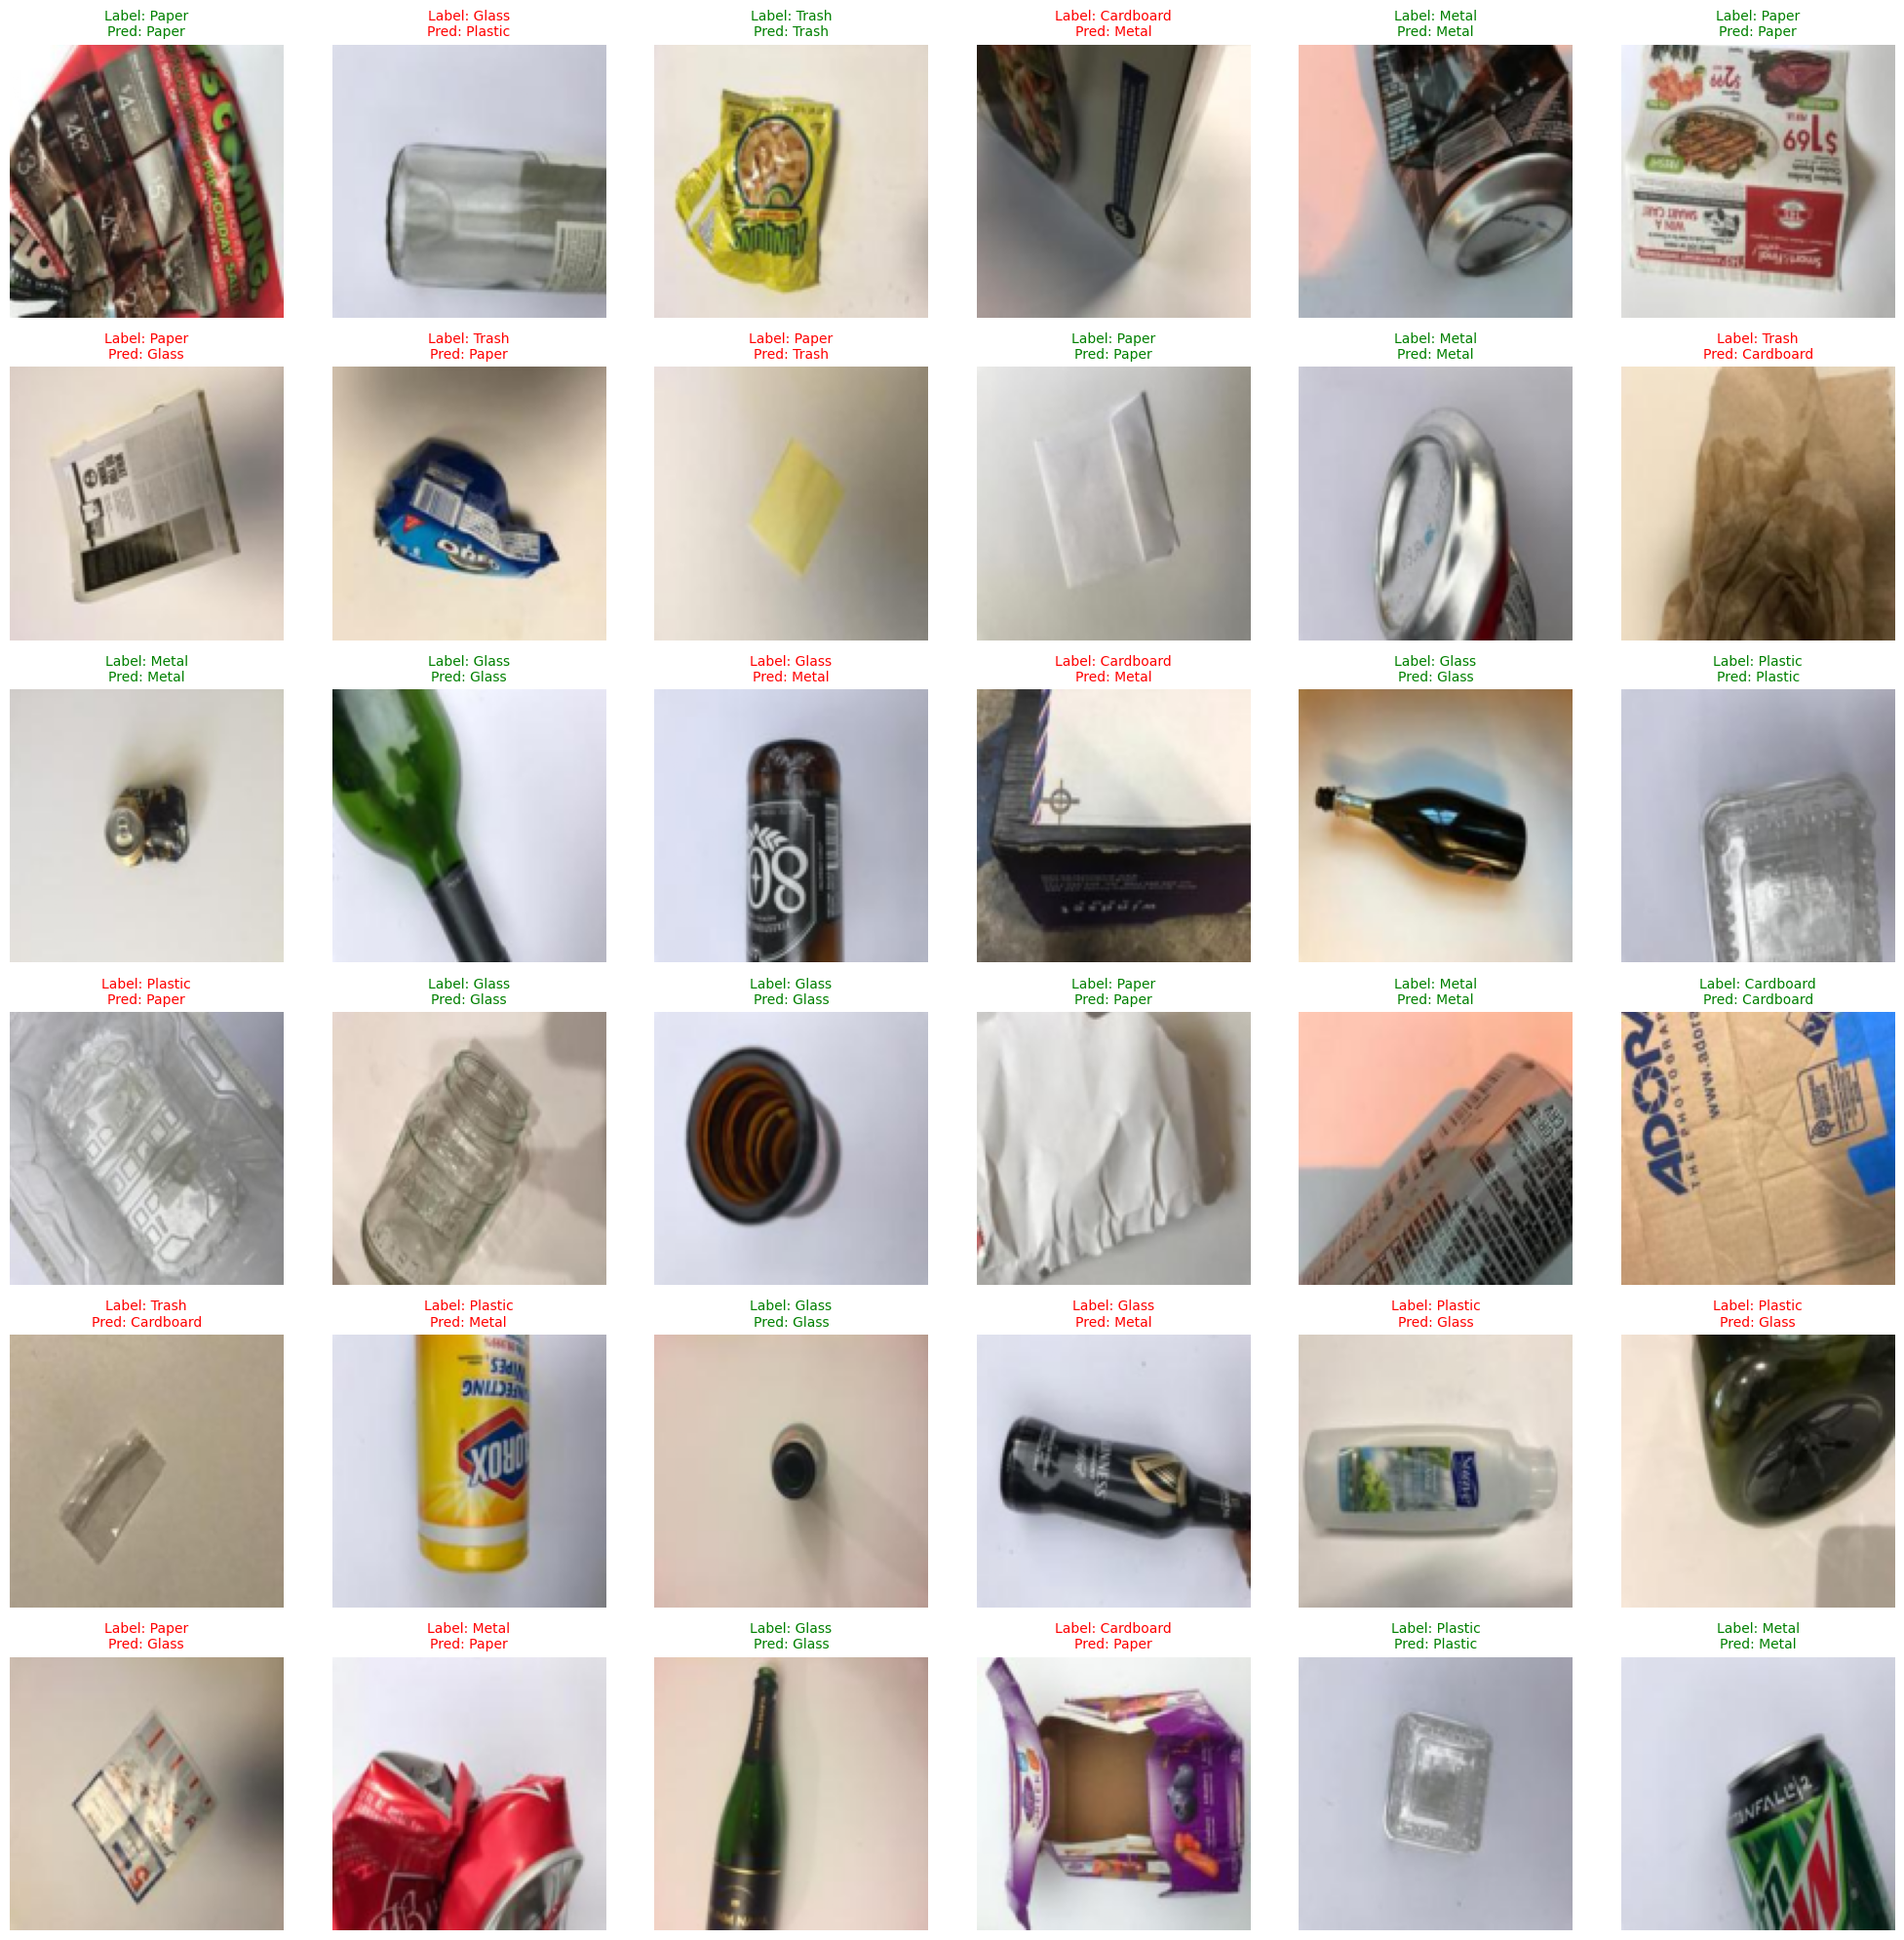

In [15]:

model.eval()
all_features = []
all_targets = []
all_preds = []

with torch.no_grad():
    # Ambil satu batch saja untuk divisualisasikan
    features, targets = next(iter(test_loader)) 
    features, targets = features.to(device), targets.to(device)
    
    outputs = model(features)
    _, preds = torch.max(outputs, 1)
    
    # Kirim ke fungsi plot
    plot_trash_results(features, targets, preds)

# With Normalize


In [17]:
batch_size = 8
crop_size = 128 

train_transform = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomVerticalFlip(0.5),
        transforms.RandomRotation(15),
        transforms.RandomResizedCrop(crop_size, scale=(0.8, 1.0)),
        transforms.ToTensor(),
        transforms.Normalize(mean=0.456, std=0.224),
    ]
)

test_transform = transforms.Compose(
    [
        transforms.Resize((crop_size, crop_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=0.456, std=0.224),
    ]
)

train_set = datasets.ImageFolder("data_CNN/train/", transform=train_transform)
train_loader = DataLoader(train_set, shuffle=True, batch_size=batch_size)

test_set = datasets.ImageFolder("data_CNN/test/", transform=test_transform)
test_loader = DataLoader(test_set, shuffle=True, batch_size=batch_size)

In [18]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 8, 3, 1, 1),  ##8 * 128 * 128
            nn.ReLU(),
            nn.MaxPool2d(2, 2), ## 8,64,64

            nn.Conv2d(8, 16, 3, 1, 1),  ##16 * 64 * 64
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #16,32,32

            nn.Conv2d(16, 32, 3, 1, 1),  ##32 * 32 * 32
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #32,16,16

            nn.Conv2d(32, 64, 3, 1, 1),  ##64 * 16* 16
            nn.ReLU(),
            nn.MaxPool2d(2, 2), #64,8,8

            nn.Conv2d(64, 128, 3, 1, 1),  ##128 * 8 * 8
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Flatten(),  ## == 128 * 4 * 4 
        )

        self.fc = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256,6),
            nn.LogSoftmax()
            )
    def forward(self,x):
        x = self.cnn(x)
        # print(x.shape)  
        x = self.fc(x)
        return x

In [19]:
from torch import nn, optim
model = CNN().to(device)
optim = optim.AdamW(model.parameters(),lr=0.005,weight_decay=1e-1)
criterion = nn.NLLLoss()
callback = Callback(model,config,outdir="model_TrashRecognition_WithNormalize")

In [ ]:
while True:
    train_acc,train_cost = fn("train",model,train_set,train_loader,criterion,optim,device)
    with torch.no_grad():
        test_acc,test_cost = fn("test",model,test_set,test_loader,criterion,optim,device)

    #Logging
    callback.log(train_cost,test_cost,train_acc,test_acc)

    #checkpoint
    callback.save_checkpoint()

    #Runtime Plotting
    callback.cost_runtime_plotting()
    callback.score_runtime_plotting() 

    # # Early Stopping
    # if callback.early_stopping(model,monitor="test_score"):
    #     callback.plot_cost()
    #     callback.plot_score()
    #     break

Train:   0%|          | 0/253 [00:00<?, ?it/s]

Test:   0%|          | 0/64 [00:00<?, ?it/s]


Epoch     4
Train_cost  = 1.5441 | Test_cost  = 1.5815 | Train_score = 0.3205 | Test_score = 0.2795 |


Train:   0%|          | 0/253 [00:00<?, ?it/s]

Test:   0%|          | 0/64 [00:00<?, ?it/s]


Epoch     4
Train_cost  = 1.5465 | Test_cost  = 1.5746 | Train_score = 0.3224 | Test_score = 0.3031 |


... (126 outputs left out)

Train:   0%|          | 0/253 [00:00<?, ?it/s]

Test:   0%|          | 0/64 [00:00<?, ?it/s]


Epoch     4
Train_cost  = 1.7248 | Test_cost  = 1.7248 | Train_score = 0.2353 | Test_score = 0.2343 |


Train:   0%|          | 0/253 [00:00<?, ?it/s]

In [20]:
import matplotlib.pyplot as plt
import numpy as np

label_names = ["Cardboard", "Glass", "Metal", "Paper", "Plastic", "Trash"]


def plot_trash_results(features, targets, preds, n_images=36):

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    fig, axes = plt.subplots(6, 6, figsize=(20, 20))
    axes = axes.flatten()

    for i in range(n_images):
        if i >= len(features):
            break
        ax = axes[i]
        img = features[i].permute(1, 2, 0).cpu().numpy()
        img = (img * std) + mean
        img = np.clip(img, 0, 1)
        ax.imshow(img)
        true_idx = targets[i].item()
        pred_idx = preds[i].item()
        is_correct = true_idx == pred_idx
        color = "green" if is_correct else "red"
        # Set Title
        ax.set_title(
            f"True: {label_names[true_idx]}\nPred: {label_names[pred_idx]}",
            color=color,
            fontsize=10,
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

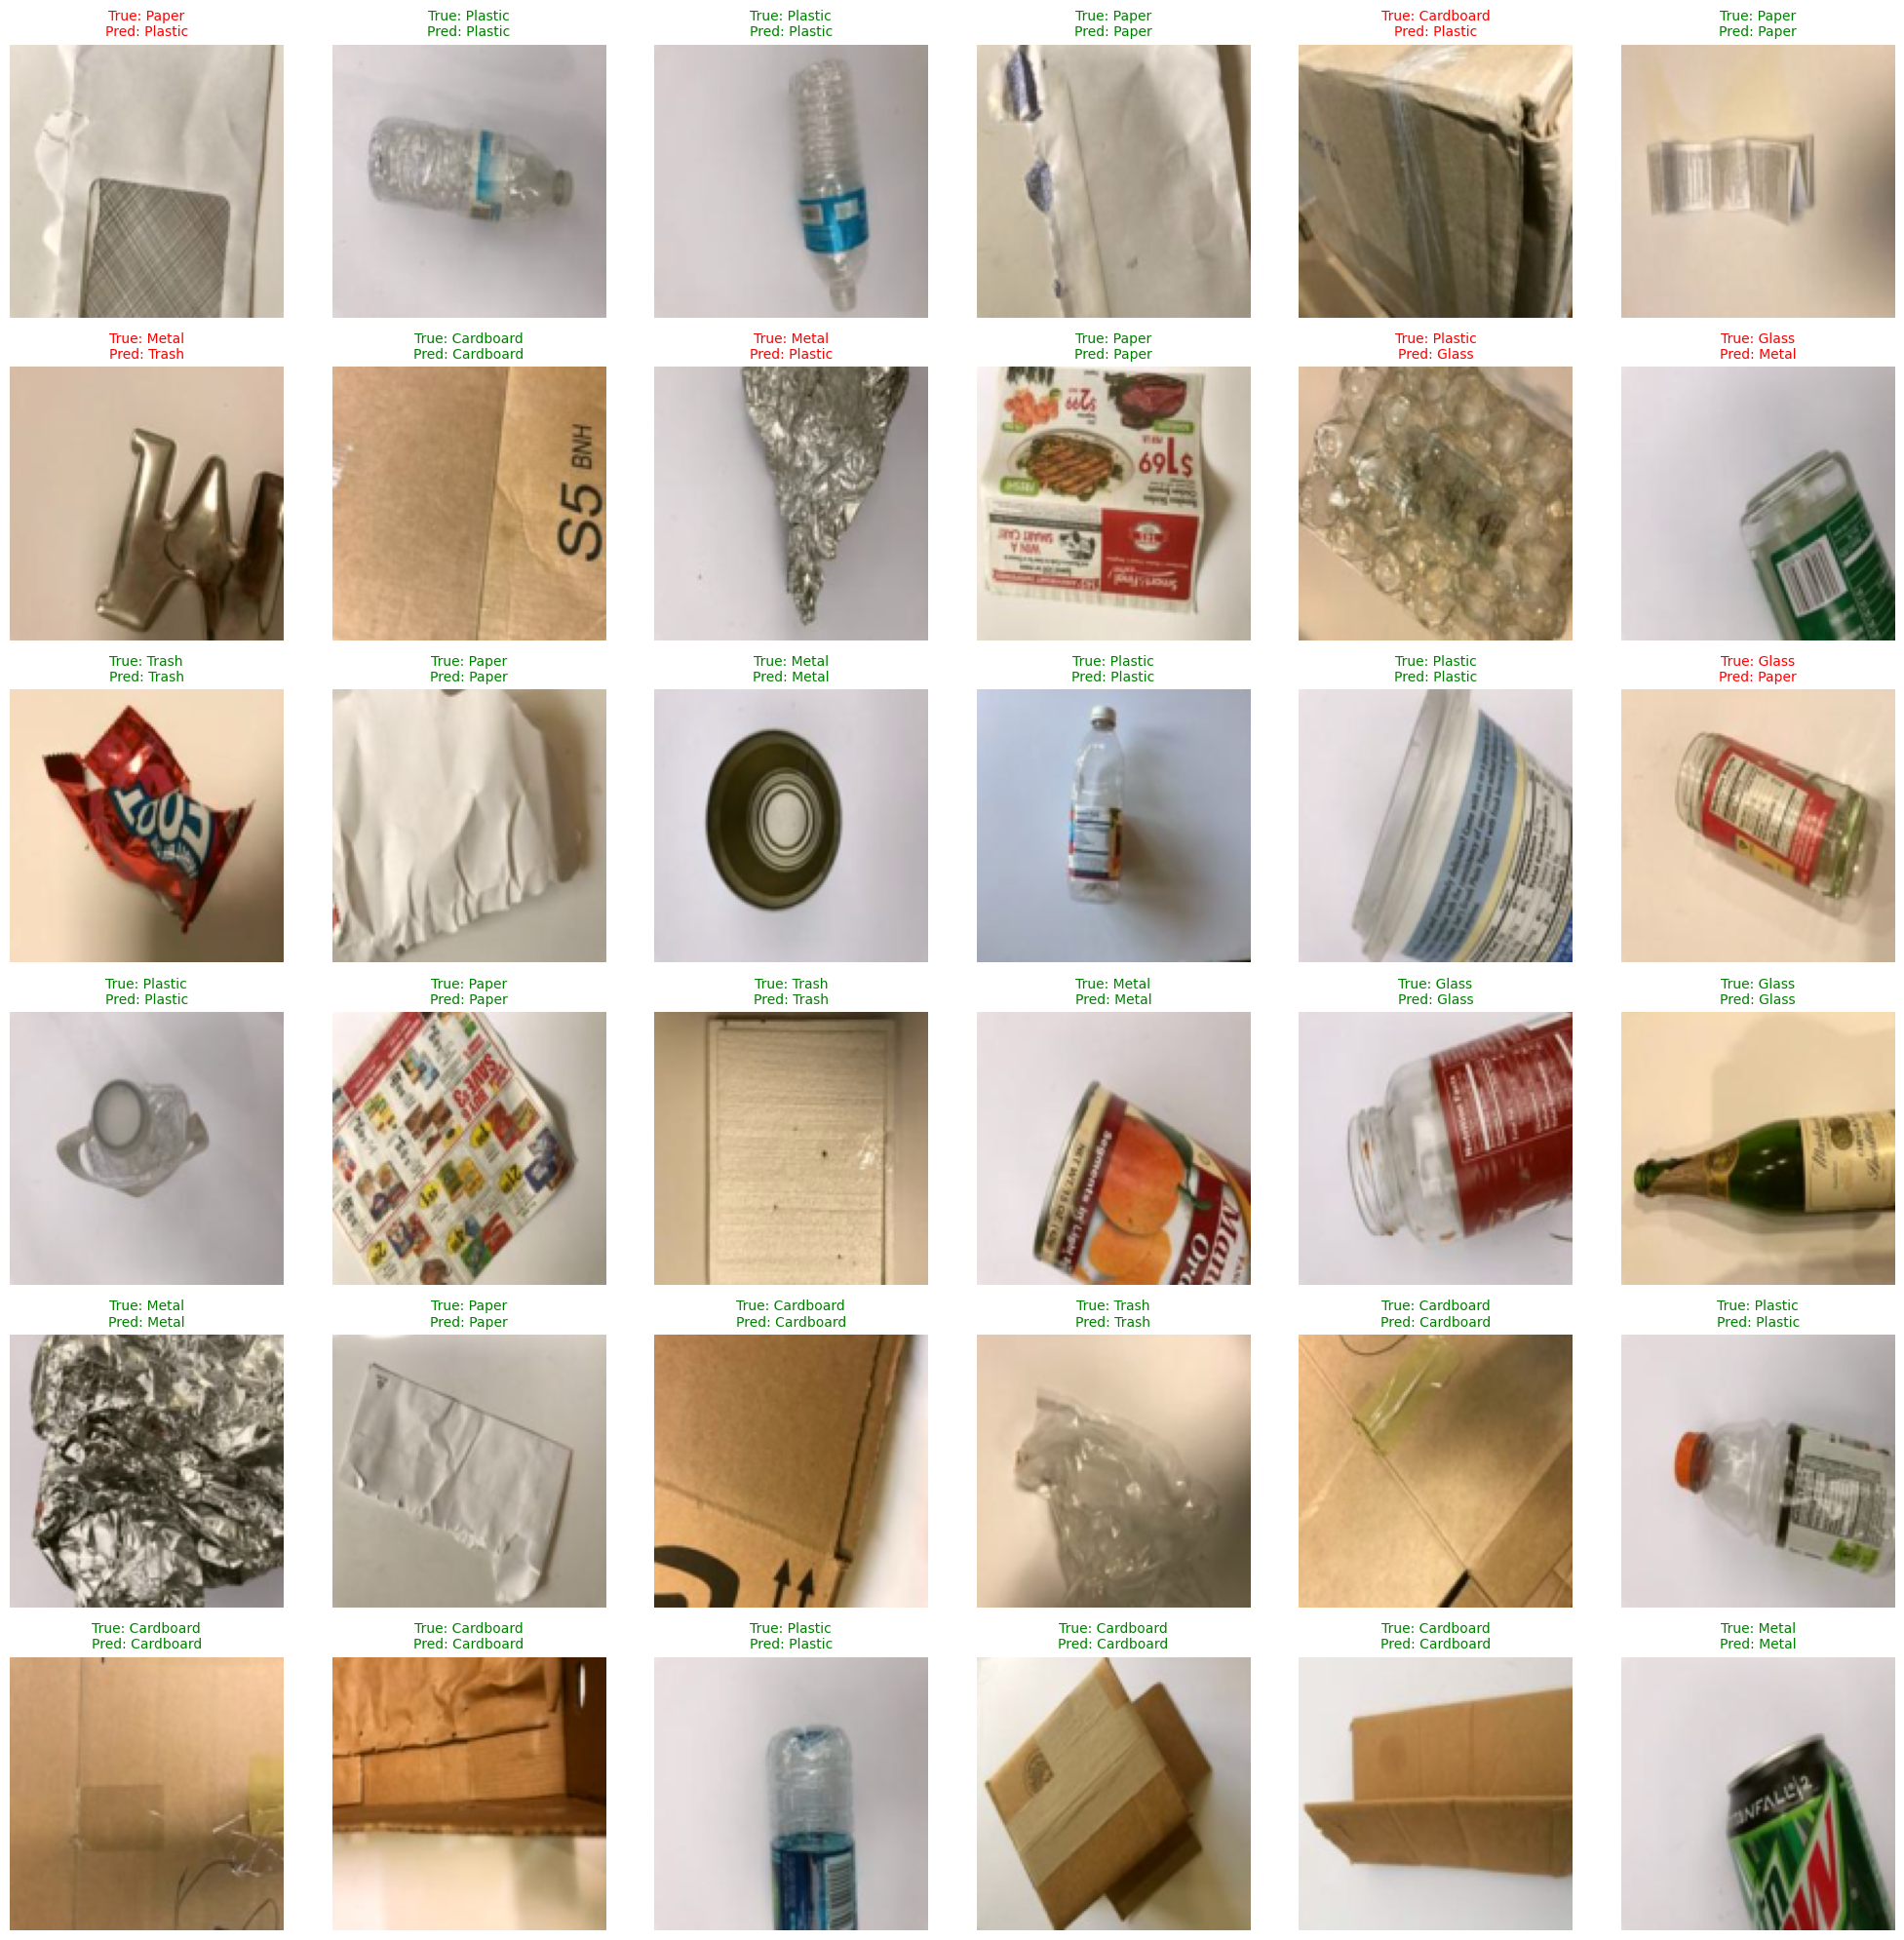

In [ ]:

model.eval()
all_features = []
all_targets = []
all_preds = []
model.to(device)
with torch.no_grad():
    features, targets = next(iter(test_loader)) 
    features, targets = features.to(device), targets.to(device)
    
    outputs = model(features)
    _, preds = torch.max(outputs, 1)
    
    plot_trash_results(features, targets, preds)

In [22]:
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        
        outputs = model(images)
            
        _, predicted = torch.max(outputs, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

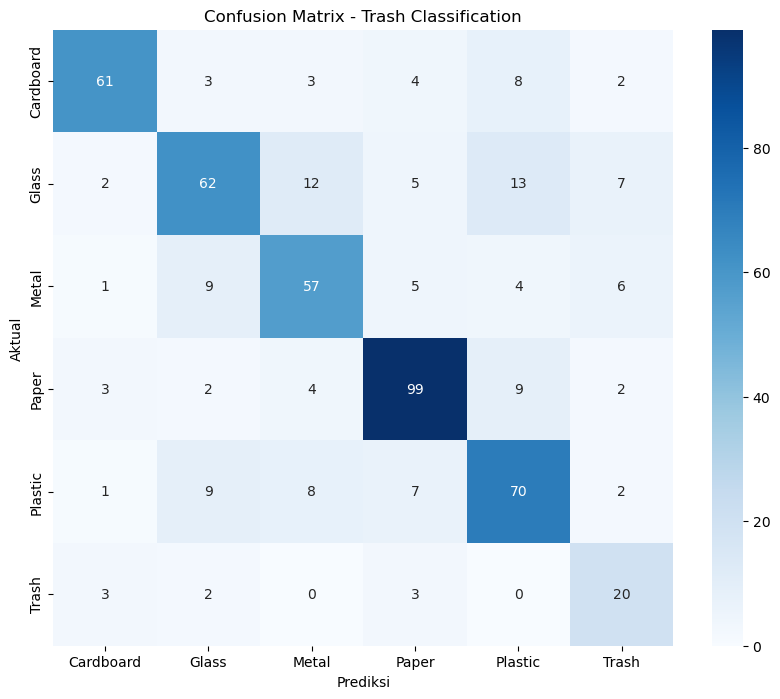

              precision    recall  f1-score   support

   Cardboard       0.86      0.75      0.80        81
       Glass       0.71      0.61      0.66       101
       Metal       0.68      0.70      0.69        82
       Paper       0.80      0.83      0.82       119
     Plastic       0.67      0.72      0.70        97
       Trash       0.51      0.71      0.60        28

    accuracy                           0.73       508
   macro avg       0.71      0.72      0.71       508
weighted avg       0.73      0.73      0.73       508



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Trash Classification')
plt.show()

print(classification_report(y_true, y_pred, target_names=label_names))

In [24]:
PATH = "trashNet_cnn_model.pth"
torch.max(outputs, 1)
torch.save(model.state_dict(), PATH)

In [25]:
load_model = CNN() 
load_model.load_state_dict(torch.load("trashNet_cnn_model.pth"))
load_model.eval()

CNN(
  (cnn): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Flatten(start_dim=1, end_dim=-1)
  )
  (fc): Sequential(
    (0): Linear(in_features=2